# CIFAR-10 image classification with a multi-branch CNN

Task 1 of the Neural Networks and Deep Learning coursework (ECS7026P), Queen Mary University of London, 2026.

Implemented by Sahar Imani. See the repository README for how the group coursework was divided.


## Environment and Hardware Configuration
Importing the core libraries for model implementation, optimisation, and visualisation of the results. A fixed random seed is specified for reproducibility, and the computational device is configured to use CUDA-enabled GPUs where available for efficiency.

In [1]:
%matplotlib inline
import time
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

In [2]:
#setting a random seed for reproducibility
torch.manual_seed(42)

#Selecting the computation device for hardware acceleration
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using {device}.')

Using cuda.


## Dataset Preparation and DataLoaders
In this section CIFAR-10 dataset is loaded for the baseline implimentation. We use `ToTensor()` transform to scale intensties to range of `[0,1]`, without initial normalisation or augmentation to evaluate the raw structural performance of the baseline model.

Then, we load the training and testing splits separately and wrapped in DataLoader objects to support efficient mini-batch processing.

Additionally, DataLoaders uses `num_workers=2` and `pin_memory=True` for effcient GPU throughput.

The batch dimensions are then checked to confirm that the network correctly recieves three-channel RGB images at a $32 \times 32$ resolution and the pipline is structurally sound and ready for training.






In [3]:
#Downloading the CIFAR-10 dataset and then loading it into memory
def load_data_cifar10(batch_size):

    # Define the transformation pipeline for the baseline implementation
    trans = [transforms.ToTensor()]
    trans = transforms.Compose(trans)

    # Load the CIFAR-10 training dataset
    cifar10_train = torchvision.datasets.CIFAR10(root='./data',train=True,transform=trans,download=True)

    #Load the CIFAR-10 testing dataset
    cifar10_test = torchvision.datasets.CIFAR10(root='./data',train=False,transform=trans,download=True)

    ## Creating DataLoaders for mini-batch training and evaluation
    return (torch.utils.data.DataLoader(cifar10_train,batch_size,shuffle=True,
                                        num_workers=2,pin_memory=True),
            torch.utils.data.DataLoader(cifar10_test,batch_size,shuffle=False,
                                        num_workers=2, pin_memory=True))

#Defining batch size
batch_size = 128

#loading the dataset
train_iter,test_iter = load_data_cifar10(batch_size)

100%|██████████| 170M/170M [00:22<00:00, 7.67MB/s]


In [4]:
#Requests the first training batch
X,y=next(iter(train_iter))

#each image is represented by a 3 x 32 x 32 tensor, images are colored so there are 3 channels (RGB)
print(f"Batch image tensor shape: {X.size()}")

#128 targets where each target is a number between 0 and 9, this classification problem has 10 classes.
print(f"Batch label tensor shape: {y.size()}")

Batch image tensor shape: torch.Size([128, 3, 32, 32])
Batch label tensor shape: torch.Size([128])


## Preliminary Architecture Verification
In line with the assignment hint, as an initial checkpoint, a simple baseline CNN is used to verify that the data pipeline, model structure, and forward pass are working correctly before moving to a custom block-based design.

This baseline model includes a well-understood architecture (Conv-ReLU-Pool) with a final linear layer for classification.
The resulting forward pass illustrates that a batch of images with shape shape $128 \times 3 \times 32 \times 32$ is mapped correctly to logits matrix of `torch.Size([128, 10])` consistent with the CIFAR-10 classification task.


In [5]:
class BaselineCNN(nn.Module):

    def __init__(self, num_outputs):
        super(BaselineCNN, self).__init__()

        # First convolutional block
        self.Conv1 = nn.Conv2d(3, 32,kernel_size=3, padding=1)
        self.ReLU1 = nn.ReLU()
        self.Pool1 = nn.MaxPool2d(kernel_size=2,stride=2)

        # second convolutional block
        self.Conv2 =nn.Conv2d(32, 64,kernel_size=3, padding=1)
        self.ReLU2 =nn.ReLU()
        self.Pool2 =nn.MaxPool2d(kernel_size=2,stride=2)

        #final classification layers
        self.Flatten =nn.Flatten()
        self.Linear= nn.Linear(64 * 8 * 8,num_outputs)

    def forward(self,x):
        #applies the first convolutional block
        x=self.Conv1(x)
        x=self.ReLU1(x)
        x=self.Pool1(x)

        #applies the second convolutional block
        x=self.Conv2(x)
        x=self.ReLU2(x)
        x=self.Pool2(x)

        ##flattens the feature maps and computes the logits
        x=self.Flatten(x)
        x=self.Linear(x)

        return x

In [6]:
num_outputs = 10
#Creating the baseline model and move to the selected device
baseline_model = BaselineCNN(num_outputs).to(device)
print('Baseline model architecture:')
print(baseline_model)

Baseline model architecture:
BaselineCNN(
  (Conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (ReLU1): ReLU()
  (Pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (Conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (ReLU2): ReLU()
  (Pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (Flatten): Flatten(start_dim=1, end_dim=-1)
  (Linear): Linear(in_features=4096, out_features=10, bias=True)
)


In [7]:
# Passes one batch through the model to verify the output shape
logits = baseline_model(X.to(device))
print(f'Logits shape after one forward pass: {logits.size()}')

Logits shape after one forward pass: torch.Size([128, 10])


## Basic Architecture - Linear Intermediate Block

This section introduces the intermediate block in its simplest form before adding improvments later on. Each block receives an input image $x$ and computes an output image $x'$ as weighted sum:

$$
x' = a_1 C_1(x) + a_2 C_2(x) + \dots + a_L C_L(x)
$$

Each branch $C_l(x)$  consists of a convolutional layer without any non-linear activation function ot batch normalisation, strictly for baseline model.

Spatial averaging (Global Average Pooling) is used to condence input feature to vector $m$. This vector passes through a fully connected layer to produce the $L$-dimensional coefficient vector $a$.

We manually adjusted the linear layer biases to `1.0`, to ensure that the gradiants flow properly from the very first epoch and avoid the multiply by zero trap inherent in near-zero weight initialisation

Also, a broadcasting mechanism is implemented by reshaping each coefficient $a_l$ into a 4D tensor ($batch\_size, 1, 1, 1$) to perform the weighted sum. So we make sure that each branch's influence is scaled appropriately across its feature maps.

The isolation test confirms that the intermediate block produces output with expected dimentions. The intermediate block correctly computes the vector $a$ and applies it to the independent convolutional layers. Further, we also confirm that all branches return feature maps of the same size enabling correct computation of weighted sums.


In [8]:
class LinearIntermediateBlock(nn.Module):
    def __init__(self, in_channels, out_channels, num_branches):
        super(LinearIntermediateBlock, self).__init__()

        self.num_branches = num_branches

        # Creating L independent convolutional branches (Strictly Linear)
        self.branches = nn.ModuleList([
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
            for _ in range(num_branches)])

        # Mapping the channel-wise averages of the input to the coefficient vector
        self.coefficient_layer = nn.Linear(in_channels, num_branches)

        #Prevents the "multiply by zero" dead-gradient trap
        nn.init.constant_(self.coefficient_layer.bias, 1.0)
        nn.init.zeros_(self.coefficient_layer.weight)

    def compute_coefficients(self, x):
        # Computing the spatial average value of each input channel (vector m)
        m=x.mean(dim=(2, 3))

        #Computes the coefficient vector (vector a)
        a=self.coefficient_layer(m)
        return a

    def forward(self, x):
        #Computing the coefficient vector for the current batch
        a=self.compute_coefficients(x)

        batch_size = x.size(0)
        x_prime =0

        # Applying every convolutional branch to the same input and computes the weighted sum
        for l, branch in enumerate(self.branches):
            branch_output = branch(x)

            #reshaping a_l to broadcast correctly across the spatial dimensions of the image
            a_l = a[:, l].view(batch_size,1, 1, 1)
            x_prime += a_l * branch_output

        return x_prime


In [9]:
#Isolation testing
num_branches=4
test_block=LinearIntermediateBlock(in_channels=3,out_channels=16,num_branches=num_branches).to(device)
X_device =X.to(device)

a=test_block.compute_coefficients(X_device)
x_prime=test_block(X_device)

print("Intermediate Block Isolation Test")
print(f'Input shape:{X_device.size()}')
print(f'Coefficient shape:{a.size()}')
print(f'Output shape:{x_prime.size()}')

Intermediate Block Isolation Test
Input shape:torch.Size([128, 3, 32, 32])
Coefficient shape:torch.Size([128, 4])
Output shape:torch.Size([128, 16, 32, 32])


In [10]:
#verifying that every convolutional branch within the block functions independently
for i, branch in enumerate(test_block.branches):
    branch_output=branch(X_device)
    print(f'Branch {i + 1} output shape: {branch_output.size()}')

Branch 1 output shape: torch.Size([128, 16, 32, 32])
Branch 2 output shape: torch.Size([128, 16, 32, 32])
Branch 3 output shape: torch.Size([128, 16, 32, 32])
Branch 4 output shape: torch.Size([128, 16, 32, 32])


##Basic Architecture - Output Block

The output block receives the final feature mapping from the intermediate blocks and computes the spatial average for each channel using Global Average Pooling (`mean(dim=(2, 3))`) to condense feature maps to a vector $m$ while keeping impotant channel information. This vector is then passed through fully contected layer to produce final 10-class logits matrix $O$.

The isolation test also verifys that model colapses 4D intermdiate feature map to 2D logits tensor `[128, 10]`.






In [11]:
class OutputBlock(nn.Module):
    def __init__(self, in_channels, num_outputs=10):
        super(OutputBlock, self).__init__()

        #mapping the channel-wise averages directly to the 10 output classes
        self.Linear=nn.Linear(in_channels, num_outputs)

    def forward(self, x):
        #computing average value of each channel (vector m)
        m=x.mean(dim=(2, 3))

        #computing the output logits (vector o)
        o=self.Linear(m)

        return o

In [12]:
num_outputs = 10  # CIFAR-10 has 10 output classes

# Creating a test output block and moves it to the selected device
test_output_block =OutputBlock(in_channels=16,num_outputs=num_outputs).to(device)

#using the output of the test intermediate block as input to the output block
logits_test=test_output_block(x_prime)

print(f'Input feature map shape:{x_prime.size()}')
print(f'Output logits shape:{logits_test.size()}')

Input feature map shape:torch.Size([128, 16, 32, 32])
Output logits shape:torch.Size([128, 10])


## Stage 1: Linear Baseline

In this section, the basic custom architecture is integrated into a `LinearBaselineCNN` to evaluate the linear baseline model. The network includes 3 intermediate blocks with increasing channel depth ($16 \rightarrow 32 \rightarrow 64$) and a final output block with $b \times 10$ logit matrix. Therefore, we use `nn.CrossEntropyLoss()`, which combines softmax activation and negative log likelihood loss. Adam optimiser is also used to ensure stable convergence towards the baseline's maximum capacity, and the initial learning rate is set to `0.001`.

Further, an evaluation helper function is created to check the accuracy of the training and testing datasets.

Additionally, a sanity check is also done before training, which confirms 10% accreucry, verifying correct random initialisation for our 10-class problem.

In [13]:
class LinearBaselineCNN(nn.Module):
    def __init__(self, num_outputs=10):
        super(LinearBaselineCNN, self).__init__()

        #Sequence of intermediate blocks with increasing channel depth
        self.B1 = LinearIntermediateBlock(in_channels=3, out_channels=16, num_branches=3)
        self.B2 = LinearIntermediateBlock(in_channels=16, out_channels=32, num_branches=3)
        self.B3 = LinearIntermediateBlock(in_channels=32, out_channels=64, num_branches=3)

        #final output block
        self.O = OutputBlock(in_channels=64, num_outputs=num_outputs)

    def forward(self, x):
        x = self.B1(x)
        x = self.B2(x)
        x = self.B3(x)
        x = self.O(x)
        return x

#initialising the model and move to the selected device
linear_baseline_model= LinearBaselineCNN(num_outputs=10).to(device)
print("Full Baseline Architecture")
print(linear_baseline_model)

Full Baseline Architecture
LinearBaselineCNN(
  (B1): LinearIntermediateBlock(
    (branches): ModuleList(
      (0-2): 3 x Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    )
    (coefficient_layer): Linear(in_features=3, out_features=3, bias=True)
  )
  (B2): LinearIntermediateBlock(
    (branches): ModuleList(
      (0-2): 3 x Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    )
    (coefficient_layer): Linear(in_features=16, out_features=3, bias=True)
  )
  (B3): LinearIntermediateBlock(
    (branches): ModuleList(
      (0-2): 3 x Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    )
    (coefficient_layer): Linear(in_features=32, out_features=3, bias=True)
  )
  (O): OutputBlock(
    (Linear): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [14]:
#Training Components Setup
#cross entropy loss required for the logits output
loss_fn=nn.CrossEntropyLoss()

#adam optimiser is a standard, stable choice for the baseline
lr=0.001
optimiser=optim.Adam(linear_baseline_model.parameters(),lr=lr)

In [15]:
# Evaluation Helpers
#Computing the average accuracy of the model across a dataset
def evaluate_metric(model,data_iter):
    model.eval()  # Setting model to evaluation mode
    correct_preds=0.0
    total_samples=0

    with torch.no_grad():  # No gradients needed for evaluation
        for X_batch,y_batch in data_iter:
            X_batch,y_batch=X_batch.to(device),y_batch.to(device)

            logits=model(X_batch)
            y_hat=logits.argmax(dim=1)

            correct_preds += (y_hat == y_batch).float().sum().item()
            total_samples += len(y_batch)

    return float(correct_preds / total_samples)

# Initial sanity check before training starts
initial_train_acc=evaluate_metric(linear_baseline_model, train_iter)
initial_test_acc =evaluate_metric(linear_baseline_model,test_iter)
print(f'\nPre-training check - Train Acc: {initial_train_acc:.4f},Test Acc: {initial_test_acc:.4f}')


Pre-training check - Train Acc: 0.1000,Test Acc: 0.1000


In [16]:
# Main Training Loop
num_epochs=10
losses=[]
train_accs=[]
test_accs=[]

print("\nInitiating Basic Training ")

for epoch in range(num_epochs):
    linear_baseline_model.train()  # Setting model back to training mode
    start_time = time.time()

    for X_batch, y_batch in train_iter:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        # Forward pass
        logits = linear_baseline_model(X_batch)
        l = loss_fn(logits, y_batch)

        # Backward pass and optimisation
        optimiser.zero_grad()
        l.backward()
        optimiser.step()

        # Store loss for plotting later
        losses.append(l.item())

    # Evaluate at the end of the epoch
    train_acc=evaluate_metric(linear_baseline_model, train_iter)
    test_acc=evaluate_metric(linear_baseline_model, test_iter)

    train_accs.append(train_acc)
    test_accs.append(test_acc)

    epoch_time=time.time()-start_time

    print(f'Epoch {epoch + 1:02d}/{num_epochs} | '
          f'Train Acc: {train_acc:.4f} | '
          f'Test Acc: {test_acc:.4f} | '
          f'Duration: {epoch_time:.1f}s')


Initiating Basic Training 
Epoch 01/10 | Train Acc: 0.2285 | Test Acc: 0.2345 | Duration: 29.8s
Epoch 02/10 | Train Acc: 0.2647 | Test Acc: 0.2704 | Duration: 28.3s
Epoch 03/10 | Train Acc: 0.2864 | Test Acc: 0.2895 | Duration: 28.3s
Epoch 04/10 | Train Acc: 0.2857 | Test Acc: 0.2940 | Duration: 27.8s
Epoch 05/10 | Train Acc: 0.2983 | Test Acc: 0.3041 | Duration: 27.9s
Epoch 06/10 | Train Acc: 0.2944 | Test Acc: 0.2943 | Duration: 28.5s
Epoch 07/10 | Train Acc: 0.3198 | Test Acc: 0.3281 | Duration: 28.5s
Epoch 08/10 | Train Acc: 0.3308 | Test Acc: 0.3336 | Duration: 28.5s
Epoch 09/10 | Train Acc: 0.3314 | Test Acc: 0.3338 | Duration: 28.5s
Epoch 10/10 | Train Acc: 0.3356 | Test Acc: 0.3405 | Duration: 27.9s


In [17]:
best_test_acc=max(test_accs)
best_epoch=test_accs.index(best_test_acc)+1

print(f"Best Baseline Testing Accuracy:{best_test_acc:.4f}")
print(f"Best Epoch:{best_epoch}")

Best Baseline Testing Accuracy:0.3405
Best Epoch:10


**Structural Limitations of the Baseline Architecture:**
Over 10 epochs, the model learns and climbs from 10% to about 34% accuracy. Notably, the slightly higher testing accuracy is not an error, it is because training accuracy is measured as running average while the model is still being updated, whereas testing accuracy is measured only after the epoch has finished, using the model’s most up-to-date weights. The models performance quickly plateaus, indicating that the model is severely underfitting. This is due to the lack of non-linear activation functions like ReLU, which causes the architecture to collapse to a single linear transformation. This linear classifier does not have the capacity to map complex nonlinear pixel distributions accurately for this task, so the performance is very low.



The batch loss graph shows that although the curve is noisy but overall downward trend indicates that the model is learning progressively from the training data.

Additionally, the training and testing accuracy across all epochs shows that training and testing accuracy remains very close to each other while slowly progressing. However, the Progress is limited due to underfitting.

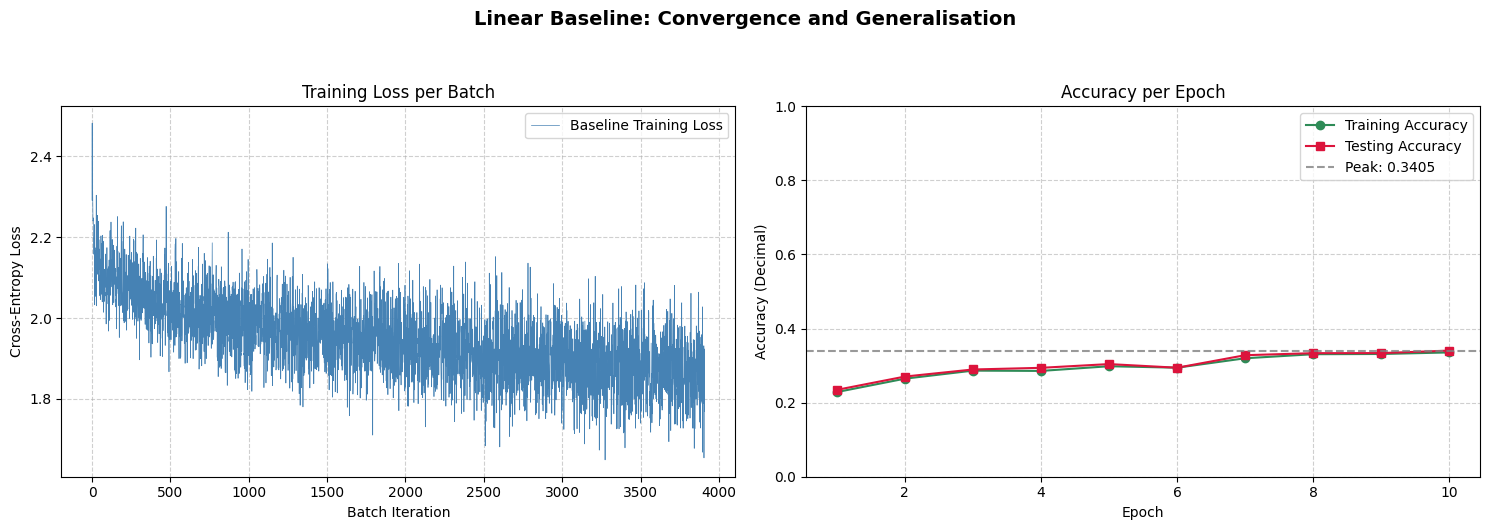

In [18]:
#Creating a unified figure
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

# Visualises training loss per batch
axes[0].plot(losses, label='Baseline Training Loss', color='steelblue', linewidth=0.5)
axes[0].set_title('Training Loss per Batch')
axes[0].set_xlabel('Batch Iteration')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

#visulising epoch wise accuracy of base line model
epochs_range = range(1, len(train_accs) + 1)
axes[1].plot(epochs_range,train_accs, label='Training Accuracy', marker='o', color='seagreen')
axes[1].plot(epochs_range,test_accs,label='Testing Accuracy', marker='s', color='crimson')

# Identifying and marking the best performance
best_baseline_acc = max(test_accs)
axes[1].axhline(y=best_baseline_acc, color='gray', linestyle='--', alpha=0.8, label=f'Peak: {best_baseline_acc:.4f}')

axes[1].set_title('Accuracy per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (Decimal)')
axes[1].set_ylim(0, 1.0)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

fig.suptitle('Linear Baseline: Convergence and Generalisation',fontsize=14,fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

## Stage 2: Deep Non-Linear Architecture

In this stage, the baseline architecture is improved by introducing non-linearity through the use of `ReLU` activation in each convolutional branch to prevent the linear collapse that we observed in the previous stage and allow the network to learn complex feature representations.

Additionally, we scaled up the architecture to 6 intermediate blocks with increasing channel depth and inserted max-pooling layers between pairs of blocks, which reduces the spatial dimensions from $32 \times 32 \rightarrow 16 \times 16 \rightarrow 8 \times 8$ to increase the receptive field of deeper layers for pattern recognition.

The non-linear architecture is trained using the standard, unaugmented dataset to observe how this increased capacity  and improved features affects learning and generalisation.


In [19]:
#Upgraded intermediate block containing ReLU activations
class NonLinearIntermediateBlock(nn.Module):
    def __init__(self, in_channels, out_channels, num_branches):
        super(NonLinearIntermediateBlock, self).__init__()
        self.num_branches = num_branches

        ## Creates L independent convolutional branches with ReLU activation
        self.branches = nn.ModuleList([
            nn.Sequential(nn.Conv2d(in_channels,out_channels,kernel_size=3,padding=1),
                          nn.ReLU(inplace=True))
            for _ in range(num_branches)])

        # maps channel wise average of inpute to coeff vector
        self.coefficient_layer=nn.Linear(in_channels,num_branches)

        #initialising coeff layer to avoid near zero branch scaling at the begining
        nn.init.constant_(self.coefficient_layer.bias, 1.0)
        nn.init.zeros_(self.coefficient_layer.weight)

    def compute_coefficients(self, x):
        #Spatial average
        m=x.mean(dim=(2, 3))

        # Computes coeff vector
        return self.coefficient_layer(m)

    def forward(self, x):
        #computes coeff vector for current batch
        a = self.compute_coefficients(x)
        batch_size=x.size(0)
        x_prime = 0

        #Appliying every branch to the same inpute and computing weighted sum
        for l, branch in enumerate(self.branches):
            branch_output=branch(x)
            a_l=a[:, l].view(batch_size, 1, 1, 1)
            x_prime += a_l * branch_output

        return x_prime

In [20]:
#Deepened non-linear model with 6 blocks and spatial pooling
class DeepNonLinearCNN(nn.Module):
    def __init__(self, num_outputs=10):
        super(DeepNonLinearCNN, self).__init__()

        #first stage of intermediate block:initial feature extraction
        self.B1 = NonLinearIntermediateBlock(3, 64, num_branches=3)
        self.B2 = NonLinearIntermediateBlock(64, 64, num_branches=3)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # second stage of intermediate block:increased channel depth
        self.B3 = NonLinearIntermediateBlock(64, 128, num_branches=3)
        self.B4 = NonLinearIntermediateBlock(128, 128, num_branches=3)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        #third stage of intermediate block: high-capacity feature representation
        self.B5=NonLinearIntermediateBlock(128, 256, num_branches=3)
        self.B6 = NonLinearIntermediateBlock(256, 256, num_branches=3)

        #Output nlock to map 256 feature channels to 10 class logits
        self.O=OutputBlock(in_channels=256, num_outputs=num_outputs)

    #Sequential propagation through non-linear blocks and pooling layers
    def forward(self, x):
        x = self.B1(x)
        x = self.B2(x)
        x = self.pool1(x)
        x = self.B3(x)
        x = self.B4(x)
        x = self.pool2(x)
        x = self.B5(x)
        x = self.B6(x)
        return self.O(x)

#initialising the model and move to the selected device
deep_nonlinear_model = DeepNonLinearCNN(num_outputs=10).to(device)
print("Full Deep Non-linear Model Architecture")
print(deep_nonlinear_model)

Full Deep Non-linear Model Architecture
DeepNonLinearCNN(
  (B1): NonLinearIntermediateBlock(
    (branches): ModuleList(
      (0-2): 3 x Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
      )
    )
    (coefficient_layer): Linear(in_features=3, out_features=3, bias=True)
  )
  (B2): NonLinearIntermediateBlock(
    (branches): ModuleList(
      (0-2): 3 x Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
      )
    )
    (coefficient_layer): Linear(in_features=64, out_features=3, bias=True)
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (B3): NonLinearIntermediateBlock(
    (branches): ModuleList(
      (0-2): 3 x Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
      )
    )
    (coefficient_layer): Linear(in_features=6

In [21]:
#defines optimiser
nonlinear_model_optimiser=optim.Adam(deep_nonlinear_model.parameters(),lr=0.001)

# Stores statistics for later plotting
losses=[]
train_accs=[]
test_accs=[]

num_epochs=15
print("\nInitiating Deep Non-linear Model Training")

for epoch in range(num_epochs):
    deep_nonlinear_model.train()  # Sets the model to training mode
    start_time=time.time()

    for X_batch, y_batch in train_iter:
        X_batch, y_batch=X_batch.to(device), y_batch.to(device)

        # Forward pass and loss calculation
        logits=deep_nonlinear_model(X_batch)
        l=loss_fn(logits, y_batch)

        # Standard Adam backpropagation and optimization
        nonlinear_model_optimiser.zero_grad()
        l.backward()
        nonlinear_model_optimiser.step()

        # Stores the batch loss
        losses.append(l.item())

    # Evaluates metrics at the end of each epoch
    train_acc =evaluate_metric(deep_nonlinear_model, train_iter)
    test_acc =evaluate_metric(deep_nonlinear_model, test_iter)
    epoch_time= time.time() - start_time

    train_accs.append(train_acc)
    test_accs.append(test_acc)

    print(f'Epoch {epoch + 1:02d}/{num_epochs} | '
          f'Train Acc: {train_acc:.4f} | '
          f'Test Acc: {test_acc:.4f} | '
          f'Duration: {epoch_time:.1f}s')


Initiating Deep Non-linear Model Training
Epoch 01/15 | Train Acc: 0.4029 | Test Acc: 0.4030 | Duration: 49.2s
Epoch 02/15 | Train Acc: 0.5533 | Test Acc: 0.5501 | Duration: 46.8s
Epoch 03/15 | Train Acc: 0.6407 | Test Acc: 0.6261 | Duration: 47.8s
Epoch 04/15 | Train Acc: 0.6964 | Test Acc: 0.6788 | Duration: 47.5s
Epoch 05/15 | Train Acc: 0.7582 | Test Acc: 0.7150 | Duration: 47.7s
Epoch 06/15 | Train Acc: 0.7985 | Test Acc: 0.7349 | Duration: 47.5s
Epoch 07/15 | Train Acc: 0.8431 | Test Acc: 0.7607 | Duration: 47.2s
Epoch 08/15 | Train Acc: 0.8681 | Test Acc: 0.7661 | Duration: 47.2s
Epoch 09/15 | Train Acc: 0.8809 | Test Acc: 0.7675 | Duration: 47.3s
Epoch 10/15 | Train Acc: 0.9364 | Test Acc: 0.7855 | Duration: 47.8s
Epoch 11/15 | Train Acc: 0.9335 | Test Acc: 0.7711 | Duration: 47.4s
Epoch 12/15 | Train Acc: 0.9524 | Test Acc: 0.7731 | Duration: 47.2s
Epoch 13/15 | Train Acc: 0.9694 | Test Acc: 0.7827 | Duration: 47.6s
Epoch 14/15 | Train Acc: 0.9788 | Test Acc: 0.7866 | Duratio

The training logs for the DeepNon-LinearCNN show clear improvement over the linear baseline model. Unlike the baseline model which had a low level of accuracy, this model learns much more effectively when non-linearity and depth are added; by epoch 15 the training accuracy is about 98%. This indicates the model has capacity to fit the training data well.

However, despite the improvement on the training set, there is a large gap between the training and test set (about 78%) exceeding about 20%. This flags overfitting of the data. By significantly increasing the model capacity without regularisation or data augmentation, the network began to memorise the training-specific pixels rather than learning generalisable structural pattern recognition rules.


The loss curve indicates overall decline across the training batch, showing that the deep non-linear model is converging.

However, the training accuracy is rising to a much higher level than the testing accuracy, indicating overfitting.

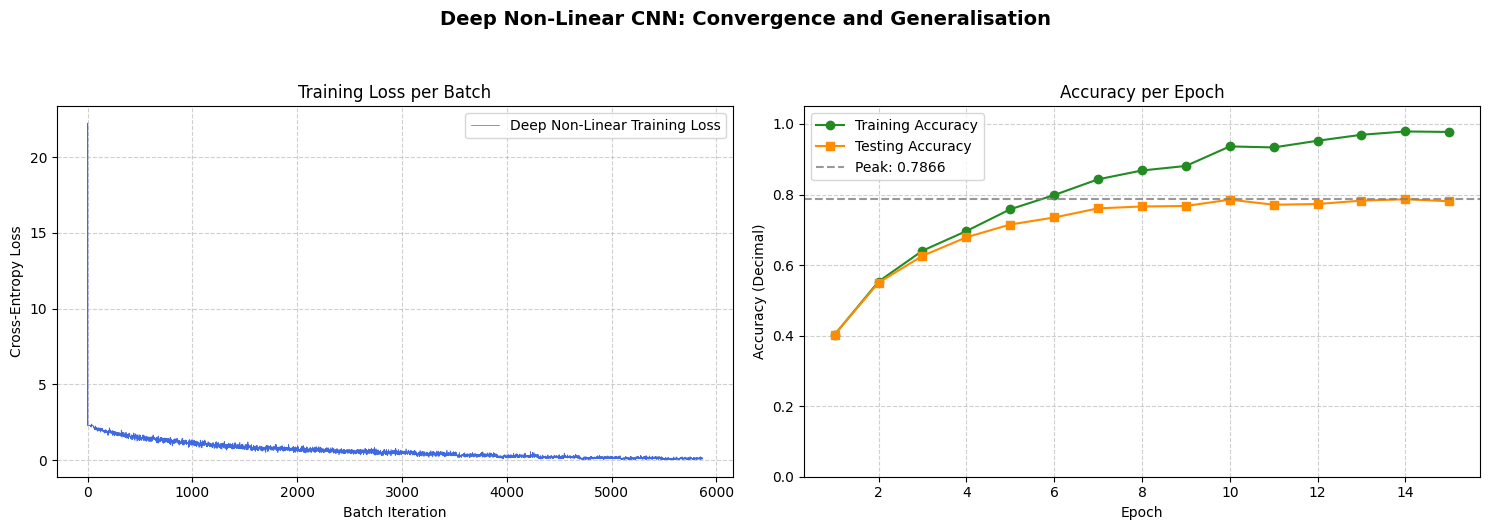

In [22]:
# Creating a unified figure
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

# Visualises training loss per batch
axes[0].plot(losses, label='Deep Non-Linear Training Loss', color='royalblue', linewidth=0.5)
axes[0].set_title('Training Loss per Batch')
axes[0].set_xlabel('Batch Iteration')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# Visualising epoch-wise accuracy of the deep non-linear model
epochs_range = range(1, len(train_accs) + 1)
axes[1].plot(epochs_range, train_accs, label='Training Accuracy', marker='o', color='forestgreen')
axes[1].plot(epochs_range, test_accs, label='Testing Accuracy', marker='s', color='darkorange')

# Identifying and marking the best performance
best_nonlinear_acc = max(test_accs)
axes[1].axhline(y=best_nonlinear_acc, color='gray', linestyle='--', alpha=0.8, label=f'Peak: {best_nonlinear_acc:.4f}')

axes[1].set_title('Accuracy per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (Decimal)')
# Scaling to 1.05 to clearly show the training accuracy approaching 100%
axes[1].set_ylim(0, 1.05)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

fig.suptitle('Deep Non-Linear CNN: Convergence and Generalisation', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

In [23]:
best_test_acc=max(test_accs)
best_epoch=test_accs.index(best_test_acc)+1

print(f"Best Non-linear Testing Accuracy:{best_test_acc:.4f}")
print(f"Best Epoch:{best_epoch}")

Best Non-linear Testing Accuracy:0.7866
Best Epoch:14


In [ ]:
# Visualisation of Training Loss per Batch
plt.figure(figsize=(10, 5))
plt.plot(losses, label='Deep Non-Linear Training Loss', color='royalblue', linewidth=0.5)
plt.title('Deep Non-Linear CNN: Training Loss per Batch')
plt.xlabel('Batch Iteration')
plt.ylabel('Cross-Entropy Loss')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

## Stage 3: Data Augmentation and Normalisation

To address the overfitting issue, we rewrite the data pipeline and include data augmentation using `RandomCrop` and `RandomHorizontalFlip`. This strategy expands the training data distribution and forces the convolutional layers to extract robust and generalisable feature representations, and it prevents the network from memorising fixed pixel cues. We normalise the input data by documented CIFAR-10 mean and standard deviation to establise the training process and prevent gradients from exploding or vanishing during early phases of training.  Normalisation is applied to the test and train data, but the spatial transformation is strictly applied to the train data.

In [25]:
def get_cifar10_augmented_loaders(batch_size=128):

    # Standard statistics for CIFAR-10 channel normalisation
    cifar_mean=(0.4914,0.4822,0.4465)
    cifar_std=(0.2023,0.1994,0.2010)

    # Augmentation, randomly modifying training samples to reduce memorisation
    train_transform = transforms.Compose([transforms.RandomCrop(32, padding=4),
                                           transforms.RandomHorizontalFlip(),
                                           transforms.ToTensor(),
                                           transforms.Normalize(cifar_mean,cifar_std)])

    # Testing: Applying only normalisation to maintain a standard evaluation baseline
    test_transform = transforms.Compose([transforms.ToTensor(),transforms.Normalize(cifar_mean,cifar_std)])

    #downloading and applying transformations
    train_data = torchvision.datasets.CIFAR10(root='./data',train=True,transform=train_transform, download=True)
    test_data = torchvision.datasets.CIFAR10(root='./data',train=False,transform=test_transform, download=True)

    # Using DataLoaders for efficient, multi-threaded batch generation
    train_iter = torch.utils.data.DataLoader(train_data, batch_size, shuffle=True,num_workers=2, pin_memory=True)
    test_iter = torch.utils.data.DataLoader(test_data, batch_size, shuffle=False, num_workers=2,pin_memory=True)

    return train_iter, test_iter

# Initialising the new data streams
aug_train_iter,aug_test_iter=get_cifar10_augmented_loaders()

In [26]:
# Re-initialising the non-linear model to isolate the effect of augmented data
augmentation_experiment_model = DeepNonLinearCNN(num_outputs=10).to(device)
print("Data Augmentation Experiment Architecture")
print(augmentation_experiment_model)

Data Augmentation Experiment Architecture
DeepNonLinearCNN(
  (B1): NonLinearIntermediateBlock(
    (branches): ModuleList(
      (0-2): 3 x Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
      )
    )
    (coefficient_layer): Linear(in_features=3, out_features=3, bias=True)
  )
  (B2): NonLinearIntermediateBlock(
    (branches): ModuleList(
      (0-2): 3 x Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
      )
    )
    (coefficient_layer): Linear(in_features=64, out_features=3, bias=True)
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (B3): NonLinearIntermediateBlock(
    (branches): ModuleList(
      (0-2): 3 x Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
      )
    )
    (coefficient_layer): Linear(in_features

In [27]:
# Lists to capture statistics for mandatory reporting
aug_only_losses = []
aug_only_train_accs = []
aug_only_test_accs = []

loss_fn = nn.CrossEntropyLoss()
optimiser_aug = optim.Adam(augmentation_experiment_model.parameters(), lr=0.001)

num_epochs = 15
print("\nStarting Training: Data Augmentation Experiment")

# Recording accuracy after each epoch for mandatory reporting
for epoch in range(num_epochs):
    augmentation_experiment_model.train()
    start_time = time.time()

    for X_batch, y_batch in aug_train_iter:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        logits = augmentation_experiment_model(X_batch)
        l = loss_fn(logits, y_batch)

        optimiser_aug.zero_grad()
        l.backward()
        optimiser_aug.step()

        # Recording batch loss
        aug_only_losses.append(l.item())

    # Evaluating metrics
    t_acc = evaluate_metric(augmentation_experiment_model,aug_train_iter)
    v_acc = evaluate_metric(augmentation_experiment_model,aug_test_iter)

    aug_only_train_accs.append(t_acc)
    aug_only_test_accs.append(v_acc)

    epoch_time = time.time() - start_time

    print(f'Epoch {epoch + 1:02d} | '
          f'Train Acc: {t_acc:.4f} | '
          f'Test Acc: {v_acc:.4f} | '
          f'Duration: {epoch_time:.1f}s')


Starting Training: Data Augmentation Experiment
Epoch 01 | Train Acc: 0.3762 | Test Acc: 0.3782 | Duration: 59.5s
Epoch 02 | Train Acc: 0.5214 | Test Acc: 0.5188 | Duration: 57.3s
Epoch 03 | Train Acc: 0.5853 | Test Acc: 0.5908 | Duration: 57.9s
Epoch 04 | Train Acc: 0.6566 | Test Acc: 0.6591 | Duration: 57.5s
Epoch 05 | Train Acc: 0.6857 | Test Acc: 0.6717 | Duration: 57.6s
Epoch 06 | Train Acc: 0.7260 | Test Acc: 0.7170 | Duration: 57.7s
Epoch 07 | Train Acc: 0.7528 | Test Acc: 0.7485 | Duration: 57.3s
Epoch 08 | Train Acc: 0.7870 | Test Acc: 0.7720 | Duration: 57.7s
Epoch 09 | Train Acc: 0.7969 | Test Acc: 0.7788 | Duration: 57.5s
Epoch 10 | Train Acc: 0.8174 | Test Acc: 0.7997 | Duration: 57.3s
Epoch 11 | Train Acc: 0.8222 | Test Acc: 0.7931 | Duration: 61.9s
Epoch 12 | Train Acc: 0.8385 | Test Acc: 0.8016 | Duration: 60.3s
Epoch 13 | Train Acc: 0.8490 | Test Acc: 0.8221 | Duration: 62.5s
Epoch 14 | Train Acc: 0.8520 | Test Acc: 0.8144 | Duration: 58.1s
Epoch 15 | Train Acc: 0.861

In [28]:
best_test_acc=max(aug_only_test_accs)
best_epoch=aug_only_test_accs.index(best_test_acc) + 1

print(f'\nBest testing accuracy: {best_test_acc:.4f}')
print(f'Best epoch: {best_epoch}')


Best testing accuracy: 0.8226
Best epoch: 15


Implementation of data augmentation yields a significant testing accuracy of 82.26% while training accuracy is 86.14%. The gap is much narrower in comparison to the previous deep non-linear stage, indicating it has reduced the overfitting, but it is not removed completely(Looking closely at the exact crossover point at Epoch 5, training permanently overtakes the testing accuracy). Another limitation is that the experiment is still lacking stronger architectural regularisation, and there is room for improvement.


As it is observed in the loss curve, training loss decreases steadily over 6,000 batch iterations, so the model is converging, and optimisation is in progress.
The accuracy graph shows that the training and testing accuracy rise consistently across epochs, indicating that the data augmentation is working and the model is learning from the heavily distorted training images rather than memorising pixel locations. However, overfitting is still observed.


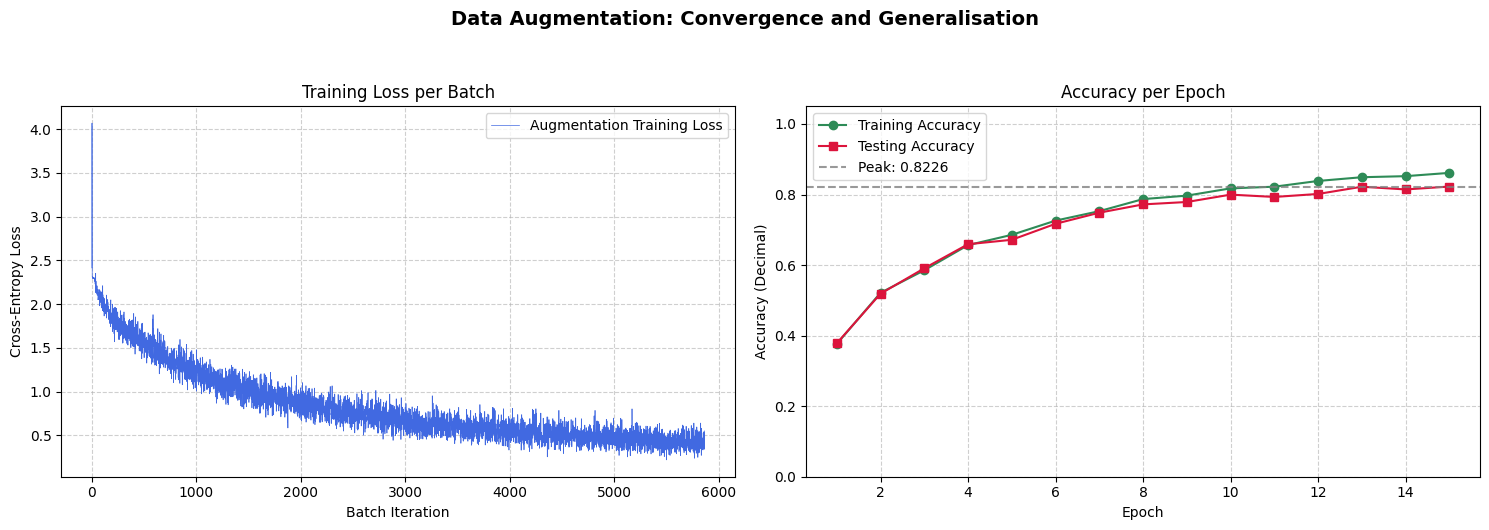

In [29]:
# Creating a unified figure
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

# Visualises training loss per batch
axes[0].plot(aug_only_losses, label='Augmentation Training Loss', color='royalblue', linewidth=0.5)
axes[0].set_title('Training Loss per Batch')
axes[0].set_xlabel('Batch Iteration')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# Visualising epoch-wise accuracy of the data augmentation experiment
epochs_range = range(1, len(aug_only_train_accs) + 1)
axes[1].plot(epochs_range, aug_only_train_accs, label='Training Accuracy', marker='o', color='seagreen')
axes[1].plot(epochs_range, aug_only_test_accs, label='Testing Accuracy', marker='s', color='crimson')

# Identifying and marking the best performance
best_aug_acc = max(aug_only_test_accs)
axes[1].axhline(y=best_aug_acc, color='gray', linestyle='--', alpha=0.8, label=f'Peak: {best_aug_acc:.4f}')

axes[1].set_title('Accuracy per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (Decimal)')
# Scaling to 1.05 to clearly show the generalisation gap
axes[1].set_ylim(0, 1.05)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

fig.suptitle('Data Augmentation: Convergence and Generalisation', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

## Stage 4: Structural Regularisation and Spatial Downsampling
To ensure stable gradient flow and convergence after the data augmentation step, we refine the architecture by integrating batch normalisation into each convolutional branch in the intermediate block. This mitigates the issue of internal covariate shift by normalising activations in each batch, and it helps to improve learning processes without divergence.

In the intermediate block, the bias term is removed from `Conv2d` layers, as batch normalisation layer makes it redundant. Also, `MaxPool2d` is used between primary blocks to reduce spatial dimensions of $16 \times 16$ and $8 \times 8$ to help with better generalisability.

In [30]:
#upgraded block using Conv2d ->BatchNorm2d ->ReLU
class RegularisedIntermediateBlock(nn.Module):
    def __init__(self, in_channels, out_channels, num_branches):
        super(RegularisedIntermediateBlock, self).__init__()

        self.num_branches = num_branches

        #Creates L independent convolutional branches with BatchNorm and ReLU
        self.branches = nn.ModuleList([
            nn.Sequential(
                # Removes bias because BatchNorm already centers the activations
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True))
            for _ in range(num_branches)])

        #Maps the channel-wise averages of the input to the coefficient vector
        self.coefficient_layer = nn.Linear(in_channels, num_branches)

        #Initialises the coefficient layer to avoid near-zero branch scaling at the start of training
        nn.init.constant_(self.coefficient_layer.bias, 1.0)
        nn.init.zeros_(self.coefficient_layer.weight)

    def forward(self, x):
        # Computes the channel-wise average vector
        m = x.mean(dim=(2, 3))

        # Computes the coefficient vector
        a = self.coefficient_layer(m)

        batch_size = x.size(0)
        x_prime = 0

        # Applies the branch weights to each branch output and computes the weighted sum
        for l, branch in enumerate(self.branches):
            a_l = a[:, l].view(batch_size, 1, 1, 1)
            x_prime += a_l * branch(x)

        return x_prime

In [31]:
# Full architecture using Batch Normalisation and hierarchical spatial reduction
class RegularisedCNN(nn.Module):
    def __init__(self, num_outputs=10):
        super(RegularisedCNN, self).__init__()

        # First stage of intermediate blocks
        self.B1 = RegularisedIntermediateBlock(3, 64, 3)
        self.B2 = RegularisedIntermediateBlock(64, 64, 3)
        self.pool1 = nn.MaxPool2d(2,2) # Reduces spatial resolution to 16 x 16

        # Second stage of intermediate blocks
        self.B3 =RegularisedIntermediateBlock(64,128,3)
        self.B4= RegularisedIntermediateBlock(128,128,3)
        self.pool2 = nn.MaxPool2d(2,2)  # Reduces spatial resolution to 8 x 8

        # Third stage of intermediate blocks
        self.B5=RegularisedIntermediateBlock(128,256, 3)
        self.B6=RegularisedIntermediateBlock(256, 256, 3)

        # Output block maps the final feature representation to 10 class logits
        self.O = OutputBlock(in_channels=256,num_outputs=num_outputs)

    def forward(self, x):
        x=self.pool1(self.B2(self.B1(x)))
        x=self.pool2(self.B4(self.B3(x)))
        x=self.O(self.B6(self.B5(x)))

        return x

In [32]:
# Architecture
stabilised_model = RegularisedCNN().to(device)
print("Full Stabilised Architecture")
print(stabilised_model)

Full Stabilised Architecture
RegularisedCNN(
  (B1): RegularisedIntermediateBlock(
    (branches): ModuleList(
      (0-2): 3 x Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
    )
    (coefficient_layer): Linear(in_features=3, out_features=3, bias=True)
  )
  (B2): RegularisedIntermediateBlock(
    (branches): ModuleList(
      (0-2): 3 x Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
    )
    (coefficient_layer): Linear(in_features=64, out_features=3, bias=True)
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (B3): RegularisedIntermediateBlock(
    (branches): ModuleLis

In [33]:
# Lists to store the statistics
batch_loss_history=[]
train_accuracy_history=[]
test_accuracy_history=[]

# Initializes the model and optimiser
stabilised_optimiser=optim.Adam(stabilised_model.parameters(),lr=0.001)

#Defines the number of training epochs
num_epochs = 20
print("\nStarting Training: Stabilised Architectural Model")

for epoch in range(num_epochs):
    stabilised_model.train()  # Ensures BatchNorm layers operate in training mode
    start_time = time.time()

    for X_batch, y_batch in aug_train_iter:
        # Transfers batch data to the active compute device
        X_batch,y_batch=X_batch.to(device),y_batch.to(device)

        # Forward pass and loss calculation
        logits =stabilised_model(X_batch)
        l =loss_fn(logits, y_batch)

        # Backpropagation and parameter update
        stabilised_optimiser.zero_grad()
        l.backward()
        stabilised_optimiser.step()

        # Stores the loss for each batch
        batch_loss_history.append(l.item())

    # Evaluates performance at the end of each epoch
    epoch_train_acc=evaluate_metric(stabilised_model, aug_train_iter)
    epoch_test_acc=evaluate_metric(stabilised_model,aug_test_iter)

    # Stores epoch-level metrics for later visualisation
    train_accuracy_history.append(epoch_train_acc)
    test_accuracy_history.append(epoch_test_acc)

    epoch_duration = time.time() - start_time

    print(f'Epoch {epoch + 1:02d}/{num_epochs} | '
          f'Train Acc: {epoch_train_acc:.4f} | '
          f'Test Acc: {epoch_test_acc:.4f} | '
          f'Duration: {epoch_duration:.1f}s')


Starting Training: Stabilised Architectural Model
Epoch 01/20 | Train Acc: 0.5610 | Test Acc: 0.5797 | Duration: 64.2s
Epoch 02/20 | Train Acc: 0.3974 | Test Acc: 0.3957 | Duration: 64.5s
Epoch 03/20 | Train Acc: 0.6626 | Test Acc: 0.6505 | Duration: 60.5s
Epoch 04/20 | Train Acc: 0.7562 | Test Acc: 0.7413 | Duration: 62.0s
Epoch 05/20 | Train Acc: 0.7295 | Test Acc: 0.7081 | Duration: 60.8s
Epoch 06/20 | Train Acc: 0.8276 | Test Acc: 0.8013 | Duration: 60.6s
Epoch 07/20 | Train Acc: 0.8155 | Test Acc: 0.7918 | Duration: 65.4s
Epoch 08/20 | Train Acc: 0.8489 | Test Acc: 0.8122 | Duration: 61.3s
Epoch 09/20 | Train Acc: 0.8291 | Test Acc: 0.8012 | Duration: 63.2s
Epoch 10/20 | Train Acc: 0.7719 | Test Acc: 0.7148 | Duration: 63.3s
Epoch 11/20 | Train Acc: 0.8714 | Test Acc: 0.8314 | Duration: 61.1s
Epoch 12/20 | Train Acc: 0.8557 | Test Acc: 0.8169 | Duration: 62.1s
Epoch 13/20 | Train Acc: 0.8839 | Test Acc: 0.8326 | Duration: 65.6s
Epoch 14/20 | Train Acc: 0.9220 | Test Acc: 0.8580 |

In [34]:
best_test_acc = max(test_accuracy_history)
best_epoch = test_accuracy_history.index(best_test_acc) + 1

print(f"Best Testing Accuracy: {best_test_acc:.4f}")
print(f"Achieved at Epoch: {best_epoch}")

Best Testing Accuracy: 0.8679
Achieved at Epoch: 17


The testing accuracy rises to 86.79% in epoch 17 in comparison to 82.26% accuracy in the previous stage, which confirms that the normalisation and regularised architecture strengthen the models accuracy. At the same time at epoch 17, the gap between the train and test is about 6%, which is a larger gap than before, showing that although the model is smarter, it is prone to overfitting. Additionally, there are visible performance drops at several points, such as around epochs 2, 10, 18, and 20. This means the model is learning, but convergence is not smooth.

The loss curve shows a strong downward trend, and in comparison to the previous stage, it drops much more sharply in the first 1,000 iterations. However, the tickness of the purple line indicates a bit of noise during training, which is rooted in batch normalisation.

The Accuracy curve shows that training and testing accuracy improve overall. However, the curves are not smooth, and there is noticeable fluctuation in some epochs. After epoch 14, the lines start flattening out and stay separated. This flags that the model has learned everything from the current model.

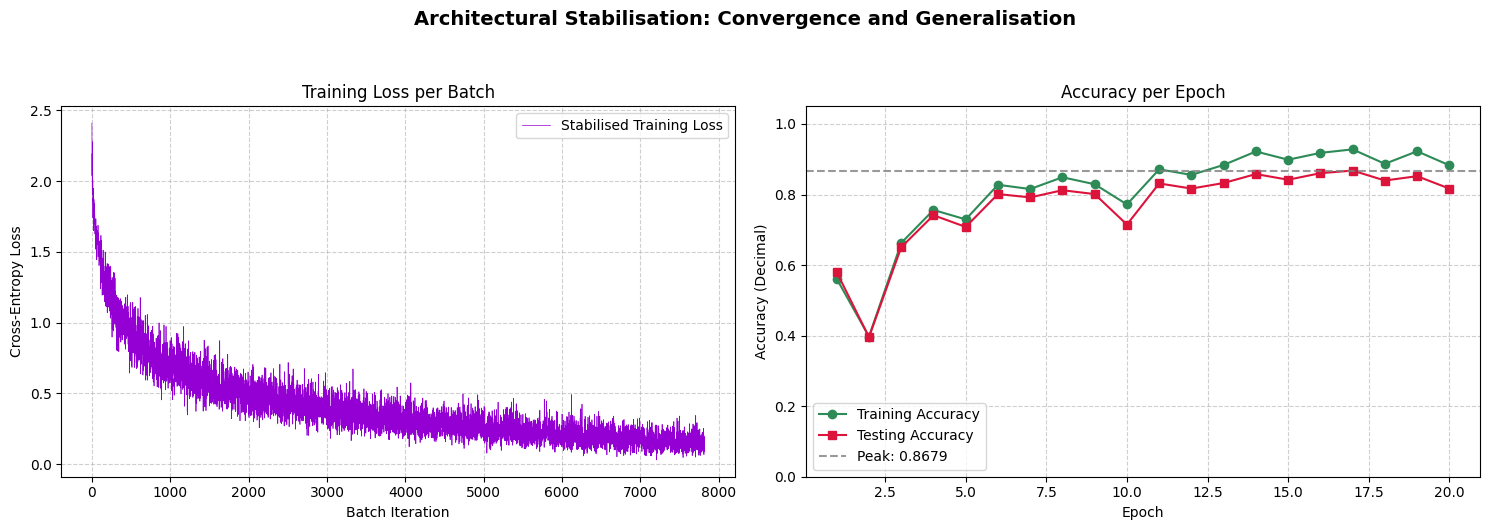

In [35]:
# Creating a unified figure
fig,axes=plt.subplots(nrows=1,ncols=2, figsize=(15,5))

# Visualises training loss per batch
axes[0].plot(batch_loss_history, label='Stabilised Training Loss',color='darkviolet',linewidth=0.5)
axes[0].set_title('Training Loss per Batch')
axes[0].set_xlabel('Batch Iteration')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# Visualising epoch-wise accuracy of the stabilised model
epochs_range = range(1, len(train_accuracy_history) + 1)
axes[1].plot(epochs_range,train_accuracy_history,label='Training Accuracy',marker='o',color='seagreen')
axes[1].plot(epochs_range,test_accuracy_history,label='Testing Accuracy',marker='s',color='crimson')

# Identifying and marking the best performance
best_stabilised_acc=max(test_accuracy_history)
axes[1].axhline(y=best_stabilised_acc, color='gray', linestyle='--', alpha=0.8, label=f'Peak: {best_stabilised_acc:.4f}')

axes[1].set_title('Accuracy per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (Decimal)')
# Scaling to 1.05 to clearly show the convergence behaviour
axes[1].set_ylim(0, 1.05)
axes[1].grid(True, linestyle='--',alpha=0.6)
axes[1].legend()

fig.suptitle('Architectural Stabilisation: Convergence and Generalisation', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

## Stage 5: Final Optimised Architecture and Training Strategy

In this final stage, we combine a set of optimisation techniques to improve generalisation and push the model past 90% accuracy rate. Although batchnormalisation stabilised the architecture, a deep model of this size is prone to overfitting through feature co-adaptation. To address this, four techniques are applied, drawing on modern training practice established by He et al. (2019) and Loshchilov & Hutter (2019). These techniques were applied in separate stages during development of this project; however, due to limitations of GPU use, they are combined in this final version of the notebook.

1. Structural Regularisation:  A dropout layer ($p=0.4$) is used before the final linear classifier, to act as a structural penalty and force the network to rely on more distributed and robust feature representations.


2. Label Smoothing: Cross-Entropy Loss is used with `label_smoothing=0.1`
 to reduce the overconfidence in the final classifier and improve the generalisability. The value 0.1 is considered the "Goldilocks" zone and acts perfectly on the CIFAR-10 dataset,it says to the network, "Be very confident it's airplane, but admit there is a 10% chance it could be something else.". It prevents the weight from exploding, and its prefect reguliser and keeps the network flexible to unseen test data(He et al., 2019).


3. Decoupled Weight Decay: AdamW Optimiser($1\times10^{-4}$ weight decay) is used instead of the Adam optimiser for stronger parameter regularisation during optimisation(Loshchilov & Hutter, 2019).


4. Navigating Local Minima: Cosine Annealing Learning Rate Scheduler (`optim.lr_scheduler.CosineAnnealingLR()`) was implemented over 50 epochs to allow larger optimisation steps in early stages and progressively smaller updates before smoothly decaying the learning rate to near zero. This helps the model to settle into an optimal local minimum without overshooting (Loshchilov & Hutter, 2019; He et al., 2019).


In [36]:
class OptimisedOutputBlock(nn.Module):
    def __init__(self, in_channels, num_outputs=10):
        super(OptimisedOutputBlock, self).__init__()

        #applies dropout before the final linear classification layer
        self.dropout = nn.Dropout(p=0.4)
        self.Linear = nn.Linear(in_channels, num_outputs)

    def forward(self, x):
        #computes the channel-wise spatial average vector
        m = x.mean(dim=(2, 3))

        # Applies dropout during training
        m = self.dropout(m)

        # Computes the output logits
        o = self.Linear(m)
        return o

In [37]:
class OptimisedCIFAR10CNN(nn.Module):
    def __init__(self, num_outputs=10):
        super(OptimisedCIFAR10CNN, self).__init__()

        # First stage of regularised intermediate blocks
        self.B1 = RegularisedIntermediateBlock(3, 64, num_branches=3)
        self.B2 = RegularisedIntermediateBlock(64, 64, num_branches=3)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Second stage of regularised intermediate blocks
        self.B3=RegularisedIntermediateBlock(64, 128, num_branches=3)
        self.B4=RegularisedIntermediateBlock(128, 128, num_branches=3)
        self.pool2=nn.MaxPool2d(kernel_size=2, stride=2)

        # Third stage of regularised intermediate blocks
        self.B5=RegularisedIntermediateBlock(128, 256, num_branches=3)
        self.B6=RegularisedIntermediateBlock(256, 256, num_branches=3)

        # Final output block with dropout regularisation
        self.O=OptimisedOutputBlock(in_channels=256,num_outputs=num_outputs)

    def forward(self, x):
        # Applies the first stage of blocks and pooling
        x = self.B1(x)
        x = self.B2(x)
        x = self.pool1(x)

        # Applies the second stage of blocks and pooling
        x=self.B3(x)
        x=self.B4(x)
        x = self.pool2(x)

        # Applies the third stage of blocks
        x=self.B5(x)
        x=self.B6(x)

        # Converts the final feature maps into class logits
        x = self.O(x)

        return x

In [38]:
# Initialises the final model and moves it to the selected device
final_model = OptimisedCIFAR10CNN().to(device)
print("Full Optimised Architecture")
print(final_model)

Full Optimised Architecture
OptimisedCIFAR10CNN(
  (B1): RegularisedIntermediateBlock(
    (branches): ModuleList(
      (0-2): 3 x Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
    )
    (coefficient_layer): Linear(in_features=3, out_features=3, bias=True)
  )
  (B2): RegularisedIntermediateBlock(
    (branches): ModuleList(
      (0-2): 3 x Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
    )
    (coefficient_layer): Linear(in_features=64, out_features=3, bias=True)
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (B3): RegularisedIntermediateBlock(
    (branches): Modul

In [39]:
# Lists to store the statistics
final_batch_loss_history =[]
final_train_accuracy_history=[]
final_test_accuracy_history=[]

# CrossEntropyLoss with label smoothing
loss_fn=nn.CrossEntropyLoss(label_smoothing=0.1)

# AdamW is used together with weight decay for stronger regularisation
optimiser_final=optim.AdamW(final_model.parameters(),lr=0.001,weight_decay=1e-4)

# Cosine annealing scheduler
num_epochs=50
scheduler=optim.lr_scheduler.CosineAnnealingLR(optimiser_final,T_max=num_epochs)

print("\nInitiating Final Optimised Training")

for epoch in range(num_epochs):
    final_model.train()  # Sets the model to training mode
    start_time = time.time()

    for X_batch,y_batch in aug_train_iter:
        X_batch,y_batch=X_batch.to(device), y_batch.to(device)

        # Forward pass and loss calculation
        logits = final_model(X_batch)
        l = loss_fn(logits, y_batch)

        # Backpropagation and parameter update
        optimiser_final.zero_grad()
        l.backward()
        optimiser_final.step()

        # Stores the batch loss
        final_batch_loss_history.append(l.item())

    # Updates the learning rate scheduler after each epoch
    scheduler.step()

    current_lr=optimiser_final.param_groups[0]['lr']

    # Evaluates the model at the end of the epoch
    train_acc=evaluate_metric(final_model, aug_train_iter)
    test_acc=evaluate_metric(final_model, aug_test_iter)
    epoch_time=time.time() - start_time

    # Stores epoch-level metrics for later visualisation
    final_train_accuracy_history.append(train_acc)
    final_test_accuracy_history.append(test_acc)

    print(f'Epoch {epoch + 1:02d}/{num_epochs} | '
          f'Train Acc: {train_acc:.4f} | '
          f'Test Acc: {test_acc:.4f} | '
          f'LR: {current_lr:.6f} | '
          f'Time: {epoch_time:.1f}s')


Initiating Final Optimised Training
Epoch 01/50 | Train Acc: 0.6068 | Test Acc: 0.5912 | LR: 0.000999 | Time: 62.9s
Epoch 02/50 | Train Acc: 0.6613 | Test Acc: 0.6514 | LR: 0.000996 | Time: 64.7s
Epoch 03/50 | Train Acc: 0.6819 | Test Acc: 0.6609 | LR: 0.000991 | Time: 60.3s
Epoch 04/50 | Train Acc: 0.5975 | Test Acc: 0.5677 | LR: 0.000984 | Time: 63.2s
Epoch 05/50 | Train Acc: 0.7158 | Test Acc: 0.6999 | LR: 0.000976 | Time: 63.9s
Epoch 06/50 | Train Acc: 0.7900 | Test Acc: 0.7705 | LR: 0.000965 | Time: 66.0s
Epoch 07/50 | Train Acc: 0.8227 | Test Acc: 0.7910 | LR: 0.000952 | Time: 61.5s
Epoch 08/50 | Train Acc: 0.8391 | Test Acc: 0.7954 | LR: 0.000938 | Time: 60.0s
Epoch 09/50 | Train Acc: 0.8927 | Test Acc: 0.8529 | LR: 0.000922 | Time: 61.1s
Epoch 10/50 | Train Acc: 0.8601 | Test Acc: 0.8450 | LR: 0.000905 | Time: 61.1s
Epoch 11/50 | Train Acc: 0.8852 | Test Acc: 0.8337 | LR: 0.000885 | Time: 63.9s
Epoch 12/50 | Train Acc: 0.8693 | Test Acc: 0.8231 | LR: 0.000864 | Time: 61.6s
Epo

In [40]:
best_test_acc = max(final_test_accuracy_history)
best_epoch = final_test_accuracy_history.index(best_test_acc) + 1

print(f"Best Final Testing Accuracy: {best_test_acc:.4f}")
print(f"Best Epoch: {best_epoch}")

Best Final Testing Accuracy: 0.9187
Best Epoch: 49


The final optimised model shows the cumulative impact of structural regularisation, label smoothing, and precision scheduling, by achieving 91.87% testing accuracy at epoch 49. The training accuracy approaches 99.97% by the end of training, this indicates that the network would likely need residual connections (ResNet) or a significant increase in depth/width.

The Cosine Annealing scheduler proved to be useful, while the first 30 epochs did the heavy lifting, in the final 20 epochs where the learning rate dropped below 0.000316 allowed the model to do small adjustments and increase the performance from about 89% to about 92%.


Despite the high training accuracy, the model did not experience catastrophic divergence, where test accuracy drops while training accuracy rises. Indicating the effectiveness of drop out and label smoothing strategy.

AdamW optimiser provided a much smoother optimisation path than the standard Adam optimiser, successfully decoupling weights decay and healthier parameter distribution.

**The limitations:**

With a training accuracy of 99.97%, the model exhausts all of its learning capacity within this framework. To improve the models' accuracy further, shifting to residual connections (ResNet) or the use of higher resolution data to overcome spatial limitations for a 32x32 CIFAR-10 format is required.


The loss curve indicates that the optimised model converges successfully. The curve shows a sharp initial descent followed by a thin plateau in the final steps. This transition from high variance noise to steady convergence to local minima proves the impact of AdamW and Cosine Annealing scheduler. Flatness of the loss curve in the final steps shows that the model has reached its error floor for this architecture.

The accuracy plot shows that the model achieves a near-perfect training accuracy of 99.97% and peak test accuracy of 91.87%, indicating the model's ability to generalise the data. The 8% gap indicates that while the model has become a master in training, it has reached its limits within the current architecture.

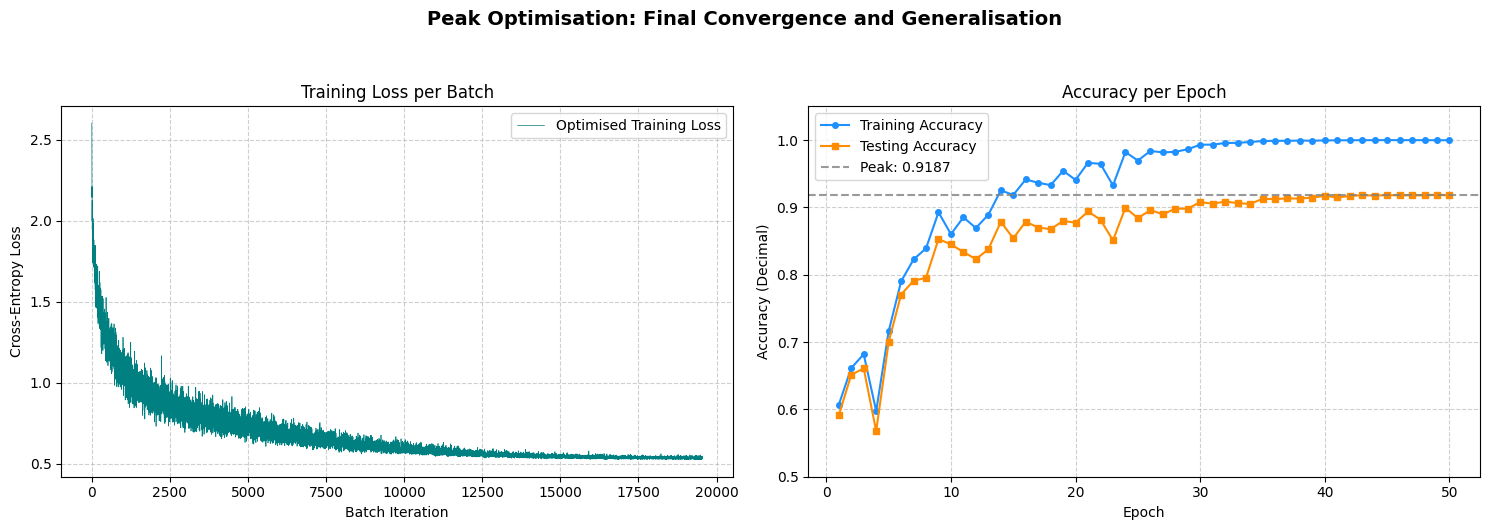

In [41]:
# Creating a unified figure
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

# Visualises training loss per batch
axes[0].plot(final_batch_loss_history, label='Optimised Training Loss', color='teal', linewidth=0.5)
axes[0].set_title('Training Loss per Batch')
axes[0].set_xlabel('Batch Iteration')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# Visualising epoch-wise accuracy of the final optimised model
epochs_range = range(1, len(final_train_accuracy_history) + 1)
# markersize is reduced to 4 to prevent the 50 data points from overlapping and looking messy
axes[1].plot(epochs_range, final_train_accuracy_history, label='Training Accuracy', marker='o', markersize=4, color='dodgerblue')
axes[1].plot(epochs_range, final_test_accuracy_history, label='Testing Accuracy', marker='s', markersize=4, color='darkorange')

# Identifying and marking the best performance
best_final_acc = max(final_test_accuracy_history)
axes[1].axhline(y=best_final_acc, color='gray', linestyle='--', alpha=0.8, label=f'Peak: {best_final_acc:.4f}')

axes[1].set_title('Accuracy per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (Decimal)')
# Scaling from 0.5 to 1.05 to clearly highlight the high-end convergence behaviour
axes[1].set_ylim(0.5, 1.05)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

fig.suptitle('Peak Optimisation: Final Convergence and Generalisation', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

## References
1.   He, T., Zhang, Z., Zhang, H., Zhang, Z., Xie, J. and Li, M. (2019) 'Bag of Tricks for Image Classification with Convolutional Neural Networks', 2019 IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR), Long Beach, CA, USA, pp. 558-567. Available at: https://doi.org/10.1109/CVPR.2019.00065.

2.  Loshchilov, I. and Hutter, F. (2019) 'Decoupled weight decay regularization', 7th International Conference on Learning Representations (ICLR), New Orleans, LA, USA. Available at: https://doi.org/10.48550/arXiv.1711.05101.